Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-variacionnye-avtoenkodery-vae

Обучим автоенкодер с двумерным ботлнеком и посмотрим на его латентное пространство

Epoch [10/10], loss_mean=0.039: 100%|██████████| 600/600 [00:18<00:00, 32.75it/s]


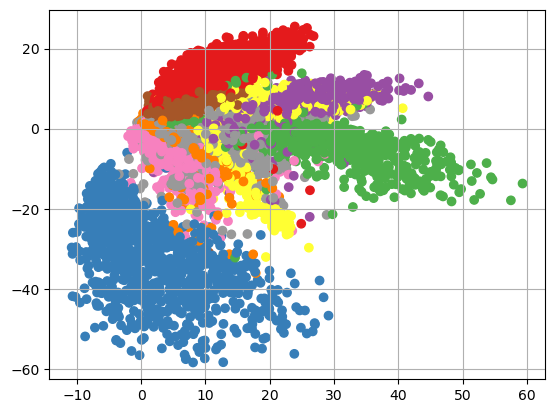

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
import torch
import torch.utils.data as data
import torchvision
import torchvision.transforms.v2 as tfs_v2
import torch.nn as nn
import torch.optim as optim


class AutoEncoderMNIST(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ELU(inplace=True),
            nn.Linear(128, 64),
            nn.ELU(inplace=True),
            nn.Linear(64, self.hidden_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(self.hidden_dim, 64),
            nn.ELU(inplace=True),
            nn.Linear(64, 128),
            nn.ELU(inplace=True),
            nn.Linear(128, output_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        h = self.encoder(x)
        x = self.decoder(h)

        return x, h


model = AutoEncoderMNIST(784, 784, 2)
transforms = tfs_v2.Compose([tfs_v2.ToImage(), tfs_v2.ToDtype(dtype=torch.float32, scale=True),
                             tfs_v2.Lambda(lambda _img: _img.ravel())])

d_train = torchvision.datasets.MNIST('mnist', download=True, train=True, transform=transforms)
train_data = data.DataLoader(d_train, batch_size=100, shuffle=True)


try:
    st = torch.load('model_vae.tar', weights_only=True)
    model.load_state_dict(st)
    
except:
    optimizer = optim.Adam(params=model.parameters(), lr=0.001)
    loss_func = nn.MSELoss()
    
    epochs = 10
    model.train()
    
    for _e in range(epochs):
        loss_mean = 0
        lm_count = 0
    
        train_tqdm = tqdm(train_data, leave=True)
        for x_train, y_train in train_tqdm:
            predict, _ = model(x_train)
            loss = loss_func(predict, x_train)
    
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    
            lm_count += 1
            loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
            train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

    st = model.state_dict()
    torch.save(st, 'model_vae.tar')


model.eval()

d_test = torchvision.datasets.MNIST(r'mnist', download=True, train=False, transform=transforms)
x_data = transforms(d_test.data).view(len(d_test), -1)

h = model.encoder(x_data)
h = h.detach().numpy()

plt.scatter(h[:, 0], h[:, 1], c=d_test.targets, cmap='Set1')
plt.grid()



Теперь посмотрим, как декодер восстановит конкретную точку из латентного пространства

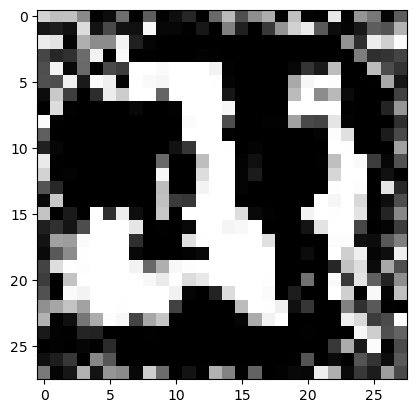

In [2]:
h = torch.tensor([-20, -30], dtype=torch.float32)
predict = model.decoder(h.unsqueeze(0))
predict = predict.detach().squeeze(0).view(28, 28)
dec_img = predict.numpy()
plt.imshow(dec_img, cmap='gray')

plt.show()

Теперь возьмем другую точку, в районе координат которой на скаттерплоте нету маркеров

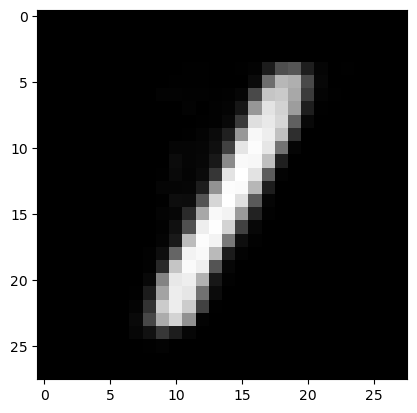

In [3]:
h = torch.tensor([10, -40], dtype=torch.float32)
predict = model.decoder(h.unsqueeze(0))
predict = predict.detach().squeeze(0).view(28, 28)
dec_img = predict.numpy()
plt.imshow(dec_img, cmap='gray')

plt.show()

Декодер выдал нечто невнятное. то есть каждой области латентного пространства пространства соответствует свой лейбл, и чтобы сгенерировать объект этого лейбла, мы должны подать на вход декодеру конкретные координаты. Таким образом, латентное пространство должно быть сжатым и компактным без разрывов. Это делают вариационные автоенкодеры. Они накладывают ограничение на латентное пространство такое, чтобы координаты соответствовали, например, нормальному распределению. Это даст нам гарантию, что любая точка (находяаяся внутри распределения, разумеется) после декодера даст осмысленный объект

На первом этапе можем попробовать добавить слои BatchNorm, так как они приводят распределение нейронов к нормальному

Epoch [10/10], loss_mean=0.041: 100%|██████████| 600/600 [00:24<00:00, 24.08it/s]


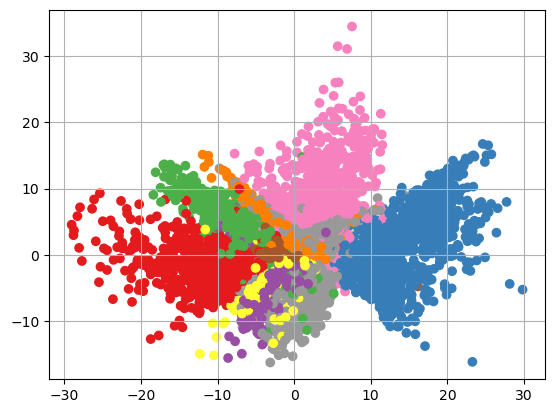

In [4]:
class AutoEncoderMNIST(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128, bias=False),
            nn.ELU(inplace=True),
            nn.BatchNorm1d(128),
            nn.Linear(128, 64, bias=False),
            nn.ELU(inplace=True),
            nn.BatchNorm1d(64),
            nn.Linear(64, self.hidden_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(self.hidden_dim, 64),
            nn.ELU(inplace=True),
            nn.Linear(64, 128),
            nn.ELU(inplace=True),
            nn.Linear(128, output_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        h = self.encoder(x)
        x = self.decoder(h)

        return x, h


model = AutoEncoderMNIST(784, 784, 2)
transforms = tfs_v2.Compose([tfs_v2.ToImage(), tfs_v2.ToDtype(dtype=torch.float32, scale=True),
                             tfs_v2.Lambda(lambda _img: _img.ravel())])

d_train = torchvision.datasets.MNIST('mnist', download=True, train=True, transform=transforms)
train_data = data.DataLoader(d_train, batch_size=100, shuffle=True)

try:
    st = torch.load('model_vae_2.tar', weights_only=True)
    model.load_state_dict(st)
    
except:
    optimizer = optim.Adam(params=model.parameters(), lr=0.001)
    loss_func = nn.MSELoss()
    
    epochs = 10
    model.train()
    
    for _e in range(epochs):
        loss_mean = 0
        lm_count = 0
    
        train_tqdm = tqdm(train_data, leave=True)
        for x_train, y_train in train_tqdm:
            predict, _ = model(x_train)
            loss = loss_func(predict, x_train)
    
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    
            lm_count += 1
            loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
            train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

    st = model.state_dict()
    torch.save(st, 'model_vae_2.tar')

model.eval()

d_test = torchvision.datasets.MNIST('mnist', download=True, train=False, transform=transforms)
x_data = transforms(d_test.data).view(len(d_test), -1)

h = model.encoder(x_data)
h = h.detach().numpy()

plt.scatter(h[:, 0], h[:, 1], c=d_test.targets, cmap='Set1')
plt.grid()

# h = torch.tensor([-40, -20], dtype=torch.float32)
# predict = model.decoder(h.unsqueeze(0))
# predict = predict.detach().squeeze(0).view(28, 28)
# dec_img = predict.numpy()
# plt.imshow(dec_img, cmap='gray')

plt.show()

это нам все еще не нравится, поэтому далее сформируем новую архитектуру, в которой за соответствие формируемого распределения нормальному будет отвечать дивергенция Кульбака-Лейблера

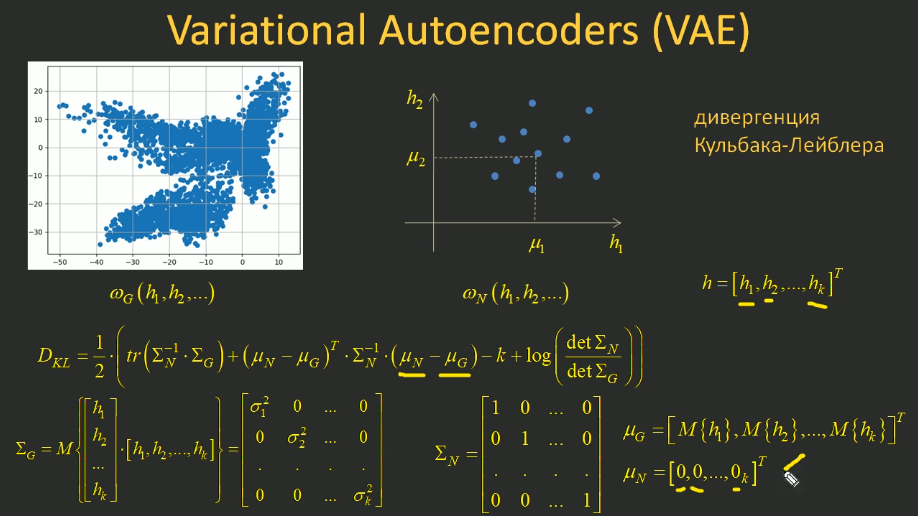

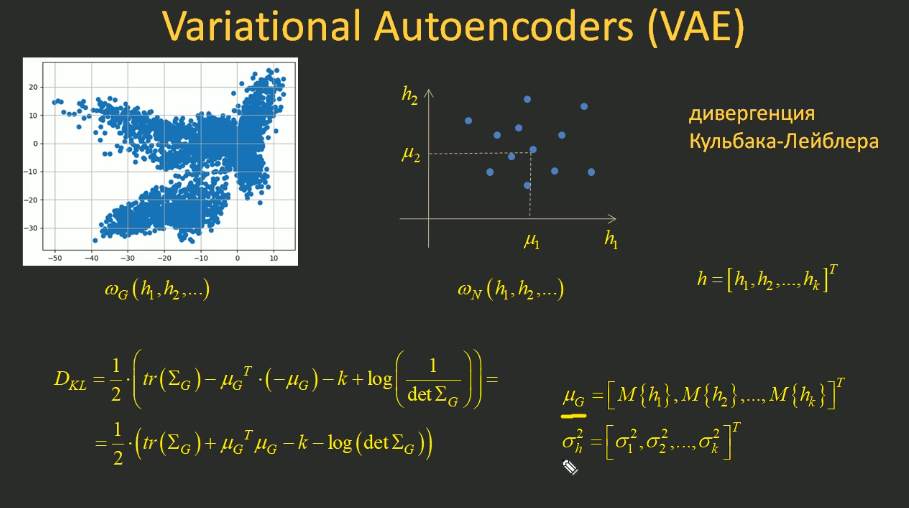

Новая архитектура предполагает, что мы будет формировать вектор средних и вектор дисперсий вместо одного вектора скрытого состояния. То есть каждый нейрон вектора будет отвечать за распределение по одной из координат латентного пространства

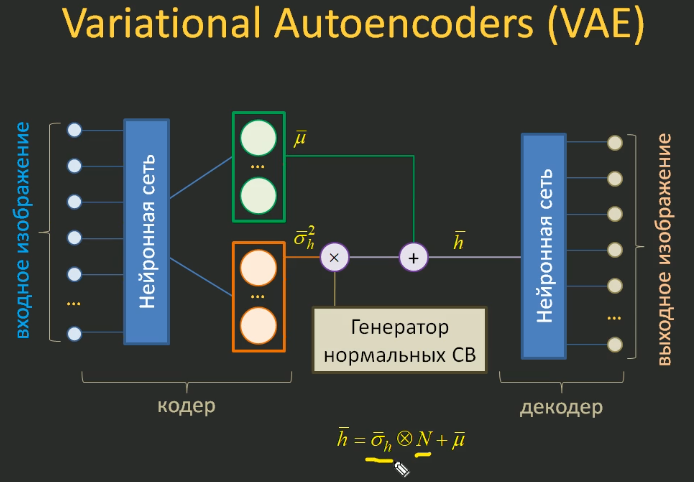

После формирования вектор среднего и дисперсии из полученных распределений сэмплируются точки и восстанавливаются декодером